# 그림 500점의 진위를 어떻게 가릴까?

**지금까지 감정한 그림은 진품 두 점과 복제품 두 점이다. 새 그림이 들어왔다. 그림마다 수치 다섯 개를 측정할 수 있다. 무엇을 근거로 진품 또는 복제품이라고 답할까?**

2025년 국제인공지능올림피아드(IOAI) 개인전에 나온 문제다. 출제진은 정답을 모르는 훈련 그림 496점의 측정값까지 활용해 판별 규칙을 만들라고 했다. 우선 아래 세 그림만 보자. A와 B의 감정 결과는 알고 있고 Q를 판별해야 한다. 손으로 풀 수 있게 수치를 두 개로 줄인 연습 자료다.

| 그림 | 첫째 측정값 | 둘째 측정값 | 감정 결과 |
|---|---:|---:|---|
| A | 0 | 5 | 복제품 |
| B | 4 | 0 | 진품 |
| Q | 3 | 4 | ? |

**먼저 답해 보자.** 첫째 측정값만 믿으면 어느 그림과 가까운가? 둘째 값만 믿으면 답이 어떻게 바뀌는가? 두 값을 모두 쓸 때 무엇을 계산할지 한 문장으로 써 보자. Q의 실제 정답은 주어지지 않았다.

이 노트북을 마치면 공개 자료에 사용할 **자기 판별식 하나와 그 식을 의심할 근거 하나**가 남는다. 수업에서는 작은 표의 판단을 코드로 확인하고 ‘내 판별식’에 첫 식과 예상까지 적는다. 자습에서는 그 식을 구현해 반례를 검증하고, 표지판 검색의 새 명세에 적용한다. ‘감정표가 따로 오면’과 배열을 복원하는 연습도 자습에서 다시 풀 수 있다. 기본 Python의 조건문·반복문·함수에서 출발한다. 노트북과 옆의 `data` 폴더를 함께 열면 같은 자료로 실행할 수 있다. [IOAI 2025 문제 원문](https://github.com/IOAI-official/IOAI-2025/blob/39558e9a639d170bd92de91958fcdc915f670463/Individual-Contest/Antique/Antique.ipynb)

## 한 줄에 어떤 답을 내야 할까?

원본 CSV의 한 행은 그림 한 점이다. `feature1`부터 `feature5`까지는 그 그림에서 읽은 수치이며, 각각 무엇을 측정했는지는 공개되지 않았다. 여섯째 열 `Authenticated`에는 감정 결과를 적었다. 진품은 $+1$, 복제품은 $-1$, 아직 감정하지 않은 그림은 $0$이다. 첫째 열에 값 $0$이 들어 있다면 그것은 측정값으로 그대로 쓴다.

새 그림에는 다섯 측정값만 들어온다. 우리가 돌려줄 것은 그림마다 $+1$ 또는 $-1$ 한 개다. 예를 들어 세 그림에 차례로 `[1, -1, -1]`을 냈다면 두 번째 줄은 두 번째 그림을 복제품이라고 판정했다는 뜻이다. 그림 번호를 정렬하거나 여섯째 열을 예측의 입력에 넣으면 문제 자체가 달라진다.

**입출력 연습.** “판정할 세 그림 중 진품이 몇 점인지 알려 달라”로 주문이 바뀌었다. 방금의 예측을 사용하면 반환값은 무엇인가? 원래 대회가 요구하는 답으로 그 값만 보낼 수 있는가? 이유를 한 줄로 적자.

In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

FEATURES = [f"feature{i}" for i in range(1, 6)]
LABEL = "Authenticated"
paintings = pd.read_csv(Path("data") / "antique_training.csv")

print("그림 수:", len(paintings))
print("측정값 열:", list(paintings[FEATURES]))
print("감정값별 개수:", paintings[LABEL].value_counts().sort_index().to_dict())
unknown_x = paintings.loc[paintings[LABEL] == 0, FEATURES]
unknown_x.head(3).round(3)

### 감정표가 따로 오면 그림을 어떻게 찾을까?

대회 원본에서는 측정값과 감정값이 한 행에 있다. 이번에 받은 작은 표는 다르다. 첫 파일에는 측정값이 있고 둘째 파일에는 일부 그림의 감정 결과가 있다. 그림의 순서도 다르다. 행끼리 위에서부터 붙이면 엉뚱한 그림을 학습하게 된다. 두 파일에서 같은 그림을 뜻하는 열을 찾아 맞춰야 한다.

아래 셀은 두 CSV를 읽는 데까지 제공한다. 먼저 **측정이 비어 있는 그림**과 **감정 기록이 없는 그림**을 손으로 찾고, 그림 번호 옆에 각각 표시하자. 숫자 0, 빈칸, 감정값 0이 서로 같은 뜻인지 판단하자. `.dtypes`는 열마다 저장된 값의 종류, `.isna()`는 비어 있는 칸을 보여 준다. `measure.merge(notes, how="left", left_on=..., right_on=...)`에서 `left`는 측정표의 모든 그림을 남긴다는 뜻이다. 두 열 이름을 골라 결합한 뒤, 감정표의 행 순서를 뒤집어도 그림별 결과가 같은지 확인하자.

In [ ]:
from io import StringIO

measure = pd.read_csv(StringIO("painting,f_a,f_b\nK7,0,5\nM2,4,\nP8,3,4\nD1,1,2\n"))
notes = pd.read_csv(StringIO("work_id,verdict\nP8,1\nM2,0\nK7,-1\n"))
print(measure.to_string(index=False))
print(notes.to_string(index=False))
# 두 표를 결합하고 비어 있는 항목, 유효한 0, 감정 기록이 없는 그림을 찾아보자.

라벨은 정답으로 확인된 부류를 가리킨다. 네 그림의 라벨만 알아도 훈련 그림의 **좌표**는 모두 볼 수 있다. 좌표끼리 가까운지, 어느 측정값이 넓게 퍼지는지 계산할 수 있다는 뜻이다.

여기에는 한계가 있다. 수직선의 $0,1$에 있는 두 그림은 복제품이고 $9,10$에 있는 두 그림은 진품이라고 하자. $4$에 있는 미상 그림의 진위는 무엇일까? 경계를 $2$에 두고 그보다 큰 값을 진품이라 해도 네 감정 결과와 맞는다. 경계를 $6$에 두어도 네 결과와 맞는다. 두 규칙은 $4$에서 **서로 다른 답**을 낸다. 미상 그림을 어떻게 쓸지는 가설로 제안하고 근거를 시험해야 한다.

아래 산점도는 미상 그림 한 점마다 점 하나를 찍는다. `feature1` 값이 같은 두 점이라도 다른 열의 값은 얼마든지 다를 수 있다. 두 축의 이름과 숫자 범위를 읽자. 물리적 단위는 공개 자료로 알 수 없다. 세로축으로 다른 열을 하나 골라 다시 그려 보자. 어떤 차이가 보이고 어떤 차이가 사라졌는가? 감정 결과를 모르는 이 그림에서 확인할 수 있는 것만 쓰자.

In [ ]:
vertical = "feature3"     # feature2, feature4, feature5 중 하나로 바꾸어 비교한다
fig, ax = plt.subplots(figsize=(6.2, 3.4))
ax.scatter(unknown_x["feature1"], unknown_x[vertical], s=14, alpha=0.45,
           color="#256078", edgecolors="none")
ax.set(xlabel="feature1", ylabel=vertical, title="496 paintings without an authentication label")
ax.grid(alpha=0.18)
fig.tight_layout()
plt.show()

## 어떤 그림의 감정 결과를 빌릴까?

A와 B 중 Q에 가까운 그림을 하나 골라 그 감정 결과를 Q의 예측으로 삼아 보자. 여기에는 **측정값이 비슷하면 진위도 같을 것이다**라는 가정이 들어 있다. 두 축의 차이를 그냥 더하면 $+3$과 $-3$이 서로 없어질 수 있다. 각 차이를 제곱한 뒤 더하면 어느 한 축에서 멀어진 만큼 거리가 커진다.

$$
D(x,q)=(x_1-q_1)^2+(x_2-q_2)^2.
$$

첫 표에서 A까지는 $(0-3)^2+(5-4)^2=10$, B까지는 $(4-3)^2+(0-4)^2=17$이다. 더 작은 값은 10이므로 A의 감정값 $-1$을 옮긴다. 실제 직선거리 $\sqrt{10},\sqrt{17}$의 순서도 같다. 가장 가까운 점 하나만 고를 때는 제곱근을 생략해도 답이 같다.

이번에는 Q와 좌표가 같은 그림 U를 후보 맨 앞에 추가해 보자. U의 감정은 아직 끝나지 않았다. **U까지의 거리가 0일 때 어느 그림의 라벨을 써야 할까?** 먼저 감정값을 빌릴 수 있는 후보를 정해야 한다.

In [ ]:
def nearest_anchor(x, y, q):
    """라벨을 빌릴 수 있는 가장 가까운 그림의 원래 행 위치를 돌려준다."""
    best_row = None
    best_distance = float("inf")
    for row, point in enumerate(x):
        if y[row] not in (-1, 1):
            continue
        distance = sum((a - b) ** 2 for a, b in zip(point, q, strict=True))
        if distance < best_distance:
            best_row = row
            best_distance = distance
    return best_row


small_x = np.array([[3, 4], [0, 5], [4, 0]])  # U, A, B
small_y = np.array([0, -1, 1])
query = np.array([3, 4])
row = nearest_anchor(small_x, small_y, query)
print("선택한 행 위치:", row, "그 행의 감정값:", small_y[row])

`best_row`는 지금까지 살핀 **감정이 끝난** 그림 중 가장 가까운 행을 기억한다. U를 지나도 값은 `None`이다. A를 보면 1을 기억하고, B는 더 멀어서 1을 유지한다. Python은 0부터 세므로 위치 1은 두 번째 그림 A다. `small_y[1]`을 읽을 때 비로소 예측 $-1$이 나온다.

동점에서는 `<`가 앞서 고른 행을 유지한다. `<=`로 바꾸면 같은 거리의 마지막 행이 남는다. 감정이 끝난 그림이 하나도 없으면 `None`이 돌아온다. 그런 경우에는 감정 결과를 빌릴 수 없으므로 예측을 멈추거나 다른 규칙을 미리 정해야 한다.

**직접 검산.** 좌표가 `[(2, 0), (0, 2), (1, 1)]`이고 감정값은 차례로 `[1, -1, 0]`이다. 새 그림 `(1, 1)`에서 선택할 행과 예측을 쓰자. 앞의 두 행을 서로 바꾸면 무엇이 바뀌는가? 손으로 쓴 뒤 앞 셀의 함수로 두 번 확인하자.

## 다섯 측정값으로 같은 계산을 하려면

원본은 측정값이 다섯 개다. 그림 $i$의 $j$번째 값을 $x_{ij}$, 새 그림에서 같은 항목을 잰 값을 $q_j$라 쓰자. 후보마다 하나씩 필요한 값은 다음과 같다.

$$ D_i=\sum_{j=1}^{5}(x_{ij}-q_j)^2. $$

∑는 **한 그림에서 다섯 칸을 차례로 더하라**는 뜻이다. 작은 표의 세 행 U, A, B에서 Q의 두 값을 빼 보자. 세 행의 차이는 $(0,0),\,(-3,1),\,(1,-4)$다. 제곱하면 $(0,0),\,(9,1),\,(1,16)$이다. 각 행을 가로로 더해야 그림별로 $0,10,17$이 남는다. 세로로 더하면 측정 항목별 숫자 두 개만 남아 어느 그림이 가까운지 답할 수 없다.

NumPy에서 `shape`는 각 방향에 몇 칸이 있는지 알려 준다. 여기서 `(3, 2) - (2,)`는 Q의 두 값을 매 행의 두 칸에 차례로 맞춰 뺀다. `axis=1`로 합하면 열 방향이 접히고 행 하나당 숫자가 하나 남는다.

In [ ]:
def squared_distances(x, q):
    differences = np.asarray(x, dtype=float) - np.asarray(q, dtype=float)
    return (differences ** 2).sum(axis=1)


print("원래 표:", small_x.shape, "새 그림:", query.shape)
print("그림별 거리제곱:", squared_distances(small_x, query))
print("항목별로 더한 경우:", ((small_x - query) ** 2).sum(axis=0))

측정기가 A와 B의 값을 한 줄 `[0,5,4,0]`으로 내보냈다면 숫자 네 개만으로는 행의 뜻을 알 수 없다. **한 그림의 두 항목이 연달아 온다**고 문서에 적혀 있으면 `reshape(2,2)`로 그림 두 행을 만든다. 반대로 같은 항목을 먼저 모아 `[0,4,5,0]`으로 보냈다면, 두 행으로 접은 다음 `.T`로 행과 열을 맞바꿔야 같은 표가 된다.

거리제곱은 차이 벡터를 자기 자신과 **내적**한 값이기도 하다. 내적은 같은 위치끼리 곱해 더하는 계산이다. A에서 Q를 뺀 `d = [-3,1]`이라면 $d\cdot d=(-3)(-3)+1(1)=10$이다. `np.dot(d, d)`로 검산할 수 있다. **손으로 확인할 과제**는 두 길이 4 배열을 그림 두 행으로 복원해 같은 거리 순위가 나오는지 시험하는 것이다. 둘째 배열을 전치하지 않으면 어느 그림의 어떤 값이 바뀌는지도 짚어 보자.

### 같은 그림인데 단위 하나를 바꾸면

첫째 열에 썼던 수를 모두 10배로 표시하자. 측정 대상은 그대로다. Q에서 A까지 거리제곱은 $30^2+1^2=901$, B까지는 $10^2+4^2=116$이다. 조금 전의 복제품 판정이 진품으로 뒤집힌다. 첫째 축의 차이가 제곱합에 **100배** 크게 반영됐기 때문이다.

한 가지 선택은 각 항목에서 평소 퍼지는 폭을 한 단위로 삼는 것이다. 훈련 열의 평균을 $\mu_j$, 표준편차를 $\sigma_j$라 하면 $z_j=(x_j-\mu_j)/\sigma_j$다. 훈련값 $t_1,\ldots,t_n$의 평균은 합을 $n$으로 나눈 값이다. **분산**은 평균에서 떨어진 차이를 제곱해 평균 낸 값이고, **표준편차**는 그 제곱근이다. 예컨대 A와 B만 사용한 첫째 축은 평균 2, 차이는 $-2,+2$, 분산은 $(4+4)/2=4$, 표준편차는 $\sqrt{4}=2$다. 세 값이 $0,0,3$이라면 평균 1, 분산 $(1+1+4)/3=2$, 표준편차는 $\sqrt{2}$다. A와 B로 돌아가면 Q의 첫째 값 3은 $(3-2)/2=0.5$다. 둘째 축의 평균과 표준편차는 각각 2.5다.

표시 단위를 10배로 바꾸면 분자와 분모도 함께 10배가 되어 $z_j$가 같다. 모든 값이 같은 훈련 열은 표준편차가 0이다. 그 열의 나눗값을 1로 두면 계산이 가능하고, 그 축에서는 어느 감정 그림을 택해도 새 점까지의 차이가 같다. 단위를 맞추는 선택에는 **각 항목에서 평소와 다른 정도를 비슷한 비중으로 믿는다**는 가정이 있다. 작은 측정 잡음까지 크게 만들 수도 있다.

같은 거리에 있는 점들을 이어 보면 왜 답이 바뀌는지 보인다. 새 점을 $(u,v)$라고 쓰자. A와 B까지의 제곱거리를 같게 놓으면 $u^2+(v-5)^2=(u-4)^2+v^2$이고, 양쪽의 $u^2,v^2$가 사라져 $8u-10v+9=0$이라는 직선이 남는다. 이 선을 넘을 때 더 가까운 그림이 바뀐다. 예를 들어 $u=3$이면 경계는 $v=3.3$이다. Q의 $v=4$는 A 쪽이다.

아래 그림에는 같은 좌표 위에 두 기준의 경계를 그렸다. 실선은 원래 단위, 점선은 첫째 값만 10배로 계산한 경계다. **두 선 사이에 놓인 점**에서는 단위를 선택하는 것만으로 정반대의 감정 결과가 나온다.

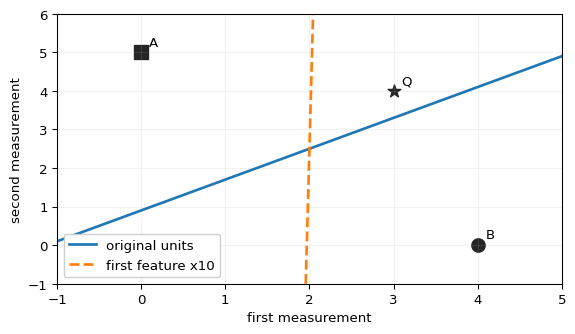

In [ ]:
def draw_boundaries():
    fig, ax = plt.subplots(figsize=(6.1, 3.6))
    v = np.linspace(-1, 6, 100)
    for multiplier, style, label in [(1, "-", "original units"), (10, "--", "first feature x10")]:
        m2 = multiplier ** 2
        u = (10 * v - 25 + 16 * m2) / (8 * m2)
        ax.plot(u, v, style, linewidth=2, label=label)
    for name, (u, v0), mark in [("A", (0, 5), "s"), ("B", (4, 0), "o"), ("Q", (3, 4), "*")]:
        ax.scatter(u, v0, s=100, marker=mark, color="#252525")
        ax.annotate(name, (u, v0), xytext=(6, 5), textcoords="offset points")
    ax.set(xlim=(-1, 5), ylim=(-1, 6), xlabel="first measurement", ylabel="second measurement")
    ax.legend(loc="lower left", framealpha=0.95)
    ax.grid(alpha=0.16)
    fig.tight_layout()
    return fig


boundary_figure = draw_boundaries()
plt.show()

In [ ]:
def fit_scale(train_x):
    train_x = np.asarray(train_x, dtype=float)
    center = train_x.mean(axis=0)
    width = train_x.std(axis=0)
    return center, np.where(width == 0, 1.0, width)


anchors = small_x[1:]     # 여기서는 감정 그림 A, B만으로 폭을 구한다
center, width = fit_scale(anchors)
z_anchors = (anchors - center) / width
z_query = (query - center) / width
print("평균:", center, "나누는 폭:", width)
print("표준화한 A, B 거리제곱:", squared_distances(z_anchors, z_query).round(2))

**새 입력에서 판단하자.** 세 행과 두 열로 된 새 훈련 표 `[(2,7), (4,7), (6,7)]`의 라벨은 `[-1,0,1]`이다. 평균과 폭은 미상 그림을 포함한 **세 행 전부**에서 계산하고, 감정값은 첫째·셋째 행에서만 빌리자. 새 그림은 `(5,8)`이다. 손으로 두 감정 그림까지의 거리제곱을 쓰고, 둘째 열이 후보 선택에 미치는 영향을 설명하자. 첫째 열을 100배로 표시하면 어떤 계산의 수치는 달라지고 어떤 판단은 유지될까? 식으로 예상한 뒤 위 함수를 이용해 확인하자.

원본의 미상 그림 496점도 이 단계에 쓰인다. 정답을 몰라도 각 열의 평균과 폭을 구하는 데 참여할 수 있다. 감정된 네 점만으로 잰 폭과, 그림 수백 점에서 잰 폭 중 어느 쪽이 새로운 그림에 알맞을지는 자료가 어떻게 모였는지에 달려 있다.

## 어떤 풀이가 더 나은지 어떻게 알아낼까?

먼저 비교 대상을 정한다. 가장 단순한 규칙은 감정 그림 중 수가 많은 부류로 모든 새 그림을 판정하는 것이다. 두 부류 수가 같으면 이 연습에서는 $+1$을 택한다. 측정값을 전혀 읽지 않는 이 규칙과 결과가 늘 같다면, 더 복잡한 계산이 어떤 그림에서 도움을 주는지 되물어야 한다.

두 번째 규칙은 **원래 측정값에서 가장 가까운 감정 그림**을 찾는다. 세 번째 규칙은 **훈련 그림 전체에서 각 열의 폭을 맞춘 뒤 가까운 감정 그림**을 찾는다. 뒤의 두 규칙은 자료가 바뀌면 기억하는 감정 그림도 달라진다. 새 그림은 계산해 둔 훈련 평균·폭으로 변환한다. 새 그림을 하나 더 받았다는 이유로 앞 그림의 판정이 바뀌어서는 곤란하다.

아래 함수는 한 번에 여러 그림을 받는다. `train`은 훈련 자료, `queries`는 판정할 그림들이다. `train[FEATURES]`라고 열 이름을 지정해 진위가 적힌 열을 거리 계산에서 빼고, 행을 받은 순서대로 답을 만든다.

In [ ]:
def predict_batch(train, queries, method):
    x = train[FEATURES].to_numpy(dtype=float)
    y = train[LABEL].to_numpy()
    q = queries[FEATURES].to_numpy(dtype=float)
    if not np.isfinite(x).all() or not np.isfinite(q).all():
        raise ValueError("계산 전에 빈 측정값을 확인하세요.")
    if not np.isin(y, [-1, 0, 1]).all():
        raise ValueError("훈련 감정값은 -1, 0, 1이어야 합니다.")
    known = np.isin(y, [-1, 1])
    if not known.any():
        raise ValueError("감정 결과를 알고 있는 그림이 필요합니다.")
    if method == "majority":
        votes = 1 if (y == 1).sum() >= (y == -1).sum() else -1
        return np.full(len(q), votes, dtype=int)
    if method == "scaled":
        center, width = fit_scale(x)
        x, q = (x - center) / width, (q - center) / width
    elif method != "raw":
        raise ValueError("알 수 없는 판별 규칙입니다.")

    anchor_x, anchor_y = x[known], y[known]
    answers = []
    for point in q:
        # argmin은 최솟값이 처음 나타나는 위치를 준다.
        nearest = np.argmin(squared_distances(anchor_x, point))
        answers.append(anchor_y[nearest])
    return np.asarray(answers, dtype=int)

### 정답을 가리는 이유

감정 그림 A를 훈련에 넣고 바로 “A를 맞혔나?”라고 물으면, A에 가장 가까운 감정 그림은 거리 0인 자기 자신이다. 그 정답을 맞힌 일은 새 그림을 판별할 근거가 약하다.

여기서는 **알려진 그림 한 점을 통째로 빼고** 나머지 499점으로 규칙을 맞춘다. 남는 것은 감정 그림 세 점과 미상 그림 496점이다. 뺀 그림의 다섯 값만 규칙에 주어 예측을 먼저 얻고, 그 다음 감정값과 맞춰 본다. 뺄 그림을 바꾸어 네 번 반복한다. 자기 그림에 투표할 기회가 사라지고 서로 다른 규칙을 똑같은 네 점에서 견줄 수 있다.

이 연습의 정확도는 ‘감정값과 일치한 예측 수 ÷ 비교할 수 있었던 그림 수’다. 네 점에서 한 점만 바뀌어도 점수가 25%포인트 움직인다. 공식 대회는 평가 자료 전체에서 채점했다. 미상 그림 496점을 맞힌 수는 여기서 셀 수 없다.

아래 두 칸은 여러 규칙을 같은 네 그림에서 비교하기 위한 채점 도구다. 먼저 제공된 상태로 실행하고, 자기가 구현할 것은 다음 절의 판별식에 집중하자.

실제 새 그림을 받을 때는 정답이 몇 점씩 섞여 있을지 알 수 없다. 판별식 안에서 사용할 수 있는 것은 전달받은 훈련 자료와 새 그림의 다섯 측정값뿐이다. 원래 표의 정답 개수나 행 번호로 빠진 답을 거꾸로 맞히면 새 그림에 적용할 수 없다.

In [ ]:
def accuracy_on_labels(y, pred):
    y, pred = np.asarray(y), np.asarray(pred)
    if y.ndim != 1 or pred.shape != y.shape:
        raise ValueError("그림당 예측 하나가 같은 순서로 필요합니다.")
    if not np.isin(y, [-1, 0, 1]).all() or not np.isin(pred, [-1, 1]).all():
        raise ValueError("감정값이나 예측값의 범위를 확인하세요.")
    known = y != 0
    if not known.any():
        raise ValueError("정확도를 계산할 감정값이 없습니다.")
    return float((pred[known] == y[known]).mean())


# 만든 예시. 세 줄 중 실제로 채점할 수 있는 것은 두 줄이다.
print(accuracy_on_labels([1, 0, -1], [1, 1, 1]))

In [ ]:
def score_folds(table, model):
    """각 감정 그림을 한 번씩 빼고 학습한다. row는 헤더를 뺀 원래 행 번호다."""
    table = table.reset_index(drop=True)
    held_rows = np.flatnonzero(table[LABEL].isin([-1, 1]))
    records = []
    for row in held_rows:
        train = table.drop(index=row).copy()
        query = table.loc[[row], FEATURES].copy()
        prediction = np.asarray(model(train, query))
        if prediction.shape != (1,) or prediction[0] not in (-1, 1):
            raise ValueError("새 그림 한 점마다 -1 또는 +1 하나가 필요합니다.")
        truth = table.at[row, LABEL]  # 모델이 답한 뒤 대조한다
        records.append((row + 1, truth, int(prediction[0])))
    return pd.DataFrame(records, columns=["row", "truth", "prediction"])


def compare_rules(table, rules):
    predictions = {}
    for name, rule in rules.items():
        result = score_folds(table, rule).set_index("row")
        predictions[name] = result["prediction"]
    return pd.DataFrame({"감정값": result["truth"], **predictions})


from functools import partial

# 세 함수 모두 (훈련 자료, 새 그림)을 받도록 판별 방법을 미리 지정한다.
rules = {
    "majority": partial(predict_batch, method="majority"),
    "raw": partial(predict_batch, method="raw"),
    "scaled": partial(predict_batch, method="scaled"),
}

## 내 판별식을 내고 반례를 찾자

목표는 **처음 보는 그림에 진위 하나를 돌려주는 규칙**을 직접 만드는 것이다. 아직 네 그림의 개별 감정 결과를 열어 보지 말자. 앞에서 쓴 기준 풀이 중 하나를 그대로 옮겨 적으면 새로 시험할 가설이 생기지 않는다.

수업은 1·2번의 식과 첫 예상까지다. 3번부터는 자기 속도로 이어 풀자.

1. **무엇을 닮음의 증거로 볼 것인가?** 사용할 측정값, 훈련 자료에서 구할 숫자, $+1$과 $-1$을 나누는 식을 써 보자. 경계에 정확히 놓인 그림의 답도 정하자. 식이 짧아도 좋다. 미상 그림의 값이 식의 어디에 들어가는지 표시하자.
2. **두 규칙의 의견이 갈릴 그림을 먼저 만들어 보자.** 수치를 작게 택해 자기 식과 기준 풀이 하나로 손계산한다. 어느 쪽에 유리한 가정을 했는지 밝히자.
3. 아래 코드 칸에서 자기 식을 함수로 구현하자. 같은 함수로 손계산한 그림의 예측을 확인한 뒤 **이 버전을 저장**한다. 그 다음에만 네 감정 그림의 결과를 열어 보자.

| 내 식과 동점 규칙 | 내가 만든 입력에서 내 예측 | 비교할 기준 풀이와 그 예측 | 의견이 갈리는 이유 |
|---|---|---|---|
| 여기에 작성 | | | |

In [ ]:
def practice_table(points, labels=None):
    """손으로 만든 두 측정값을 공식 함수의 다섯 열에 맞춘다."""
    table = pd.DataFrame(points, columns=FEATURES[:2])
    for column in FEATURES[2:]:
        table[column] = 0.0
    if labels is not None:
        table[LABEL] = labels
    return table


# 입력 방식을 보여 주는 예. 의견이 갈릴 값과 감정 결과는 자신이 정한다.
paper_train = practice_table([[0, 5], [4, 0]], [-1, 1])
paper_query = practice_table([[3, 4]])
print(predict_batch(paper_train, paper_query, "raw"))
# 내 함수를 정의한 뒤 my_rule(paper_train, paper_query)와 대조한다.

In [ ]:
# 이 칸에 my_rule(train, queries)를 정의한다.
# train에는 감정값 열이 있고 queries에는 다섯 측정값만 있다.
# queries의 순서대로 -1 또는 +1을 하나씩 담은 1차원 리스트나 배열을 돌려준다.
#
# 손계산을 확인한 다음, 자기 함수 아래에 이 한 줄을 넣고 실행한다.
# rules["내 식"] = my_rule

In [ ]:
# 내 식을 등록하기 전에는 개별 감정값도 기준 풀이의 결과도 열지 않는다.
if "내 식" in rules:
    comparison = compare_rules(paintings, rules)
    print(comparison.to_string())
    for name in rules:
        hits = (comparison[name] == comparison["감정값"]).sum()
        print(name, f"{hits}/{len(comparison)}",
              f"{accuracy_on_labels(comparison['감정값'], comparison[name]):.0%}")
else:
    print("자기 식과 손계산을 기록하고 위 코드 칸에서 규칙을 등록하세요.")

**다수결의 결과를 설명해 보자.** 네 그림에서 이 규칙이 낸 예측을 실제 감정값과 한 줄씩 대조하자. 원래 네 점의 구성과 한 점씩 빼는 방법이 결과에 어떤 영향을 주었는가? 같은 일이 새 그림에서도 일어날 것이라고 말할 수 있는가?

**몇 점 맞혔는가에서 한 걸음 더.** 같은 점수라도 틀린 그림은 다를 수 있다. 결과표에서 두 방법의 답이 다른 행 하나를 골라, 그 그림이 각 방법에서 어느 쪽에 가까웠는지 수치로 되짚자. 네 행에서 차이가 없다면 앞서 만든 경계 사례에서 무엇이 달랐는지 설명하자. 어떤 추가 감정 결과를 얻으면 두 가설 중 하나를 포기할 수 있을까?

판정을 바꾸고 싶다면 첫 식·첫 예측을 남기고 **무엇을 보고 어디를 바꿨는지** 적자. 네 정답을 본 뒤 고친 규칙의 네 점 점수는 탐색 결과다. 여전히 말할 수 있는 것, 새로 감정한 그림에서 다시 확인해야 할 것을 나누어 적자.

이제 네 점의 분포를 열어 볼 수 있다. 다음 그림은 첫째 측정값 하나만 보여 준다. 점 하나가 감정 그림 한 점이다. 점 두 개씩만 보고 “이 값 하나로 진품과 복제품을 가를 수 있다”고 말할 수 있는지 생각해 보자. 세로 위치는 부류 이름을 읽기 위한 것이며 측정값의 크기를 뜻하지 않는다.

In [ ]:
if "내 식" in rules:
    chosen_feature = "feature1"  # 자기 식에서 중요하다고 본 열로 바꾸어 그린다
    known_paintings = paintings.loc[paintings[LABEL].isin([-1, 1])].copy()
    known_paintings["class_name"] = known_paintings[LABEL].map({1: "authentic", -1: "replica"})
    fig, ax = plt.subplots(figsize=(6.2, 2.4))
    sns.stripplot(data=known_paintings, x=chosen_feature, y="class_name",
                  order=["replica", "authentic"], jitter=False, size=9, color="#9c4a2b", ax=ax)
    ax.set(xlabel=chosen_feature, ylabel="", title="Four authenticated paintings")
    fig.tight_layout()
    plt.show()
else:
    print("가설을 저장한 뒤 감정 그림의 분포를 확인합니다.")

## 새 명세를 읽고 풀이를 고쳐 보자

다른 IOAI 개인전 과제에서는 표지판 사진을 받아 **같은 화장실에 붙은 반대 성별 표지판의 사진 번호**를 돌려줘야 했다. 베이항대학교 출제팀이 만든 대회 과제에서는 사진의 특징과 대응 관계를 모델이 학습한다. 평가 사진과 후보 사진의 번호는 따로 섞여 있다. 번호가 같다는 것만으로 서로 짝지을 수 없다. [Restroom Icon Matching 원문 2–5절](https://github.com/IOAI-official/IOAI-2025/blob/39558e9a639d170bd92de91958fcdc915f670463/Individual-Contest/Restroom/Restroom.ipynb)

아래는 **후보 선택만 떼어 낸 새 과제**다. 사진마다 성별 표시와 특징 수치 두 개가 이미 주어졌다. 연습용 검색기는 반대 성별 후보 가운데 두 특징의 제곱거리 합이 가장 작은 사진의 **번호**를 반환해야 한다. 같은 거리면 번호가 작은 사진을 택한다. 가능한 후보가 없으면 `None`을 반환한다. 실제 같은 화장실인지 판정할 정답은 주어지지 않았다.

질의 사진은 번호 40, 표시 M, 특징 $(1,1)$이다. 목록의 숫자는 파일 이름에 붙은 번호다.

| 후보 번호 | 표시 | 특징 |
|---:|:---:|---:|
| 8 | M | (1, 1) |
| 40 | F | (3, 1) |
| 12 | F | (1, −1) |
| 56 | F | (4, 1) |

**코드를 보기 전에** 가능한 후보와 거리를 쓰고 반환값을 정하자. 목록의 줄을 뒤집으면 그 값도 바뀌어야 할까? 표시를 모두 M으로 바꾸면 어떨까? 그림 판별 함수의 어느 계산을 재사용하고 어느 결정을 바꿔야 하는지 적은 뒤 직접 함수를 쓰자.

In [ ]:
query_icon = (40, "M", (1, 1))
gallery = [(8, "M", (1, 1)), (40, "F", (3, 1)),
           (12, "F", (1, -1)), (56, "F", (4, 1))]
# 여기에 match_icon(query_icon, gallery)를 작성한다.
# 원래 표, 줄을 뒤집은 표, 반대 표시가 없는 표에서 손계산과 비교한다.

**마지막 질문.** 연습용 검색기가 명세대로 작동한다는 것과 실제 화장실의 짝을 잘 찾는다는 것을 확인하려면 각각 어떤 자료가 필요한가? 그림 진위 판별로 돌아가 같은 차이를 설명하자. 이 둘을 구분하면 다음 주에 어느 그림을 훈련에 남기고 어느 그림을 평가에 빼 둘지 스스로 정할 수 있다.

### 더 탐구하고 싶다면 · 미상 그림의 위치가 바뀌면

한 측정값에서 복제품은 0, 진품은 2에 있다. 미상 그림 다섯 점씩이 각각 $-0.1$과 $1.5$에 몰려 있다. 새 그림 $0.9$를 가장 가까운 감정 그림으로 판정하면 어느 쪽인가?

이번에는 밀집한 곳에서 나온 측정값이 더 믿을 만하다고 가정한다. 각 감정 그림과 새 그림을 **현재 좌표 하나와 가장 가까운 다른 훈련 그림 다섯 점의 좌표를 모두 더해 6으로 나눈 곳**으로 한 번만 옮겨 보자. 이웃은 옮기기 전 좌표에서 골라야 한다. 새 그림은 훈련 그림의 이웃이 될 수 없다. 옮긴 두 감정 그림 중 새 그림에 가까운 쪽을 고르면 어떻게 되는가? 두 풀이가 다른 답을 낸다면, 각각 어느 상황에서 틀릴지 설명하자. 미상 그림의 위치가 예측을 바꿨다는 사실만으로 진위를 확인할 수 있을까?

### 제출 형식을 확인할 때 펼쳐 보기

공식 `Antique`에서는 실행하면 `submission.zip`을 만드는 `submission.ipynb`를 제출한다. 예측 대상 A와 B에는 그림이 500점씩 있다. `submission.zip` 안에 `submissionA.csv`와 `submissionB.csv`를 넣으며, 각 파일의 한 줄에는 원래 그림 순서대로 `-1` 또는 `1` 하나만 쓴다. 맨 윗줄의 열 이름이나 그림 번호도 보내지 않는다. 아래 도우미는 교육용으로 만든 형식 검사다. 손에 있는 짧은 예측으로 파일을 열어 볼 수 있다.

In [ ]:
from io import BytesIO
from zipfile import ZipFile


def make_submission(pred_a, pred_b, expected_sizes):
    buffer = BytesIO()
    with ZipFile(buffer, "w") as archive:
        for name, pred, size in zip(("submissionA.csv", "submissionB.csv"),
                                    (pred_a, pred_b), expected_sizes, strict=True):
            values = np.asarray(pred)
            if values.shape != (size,) or not np.isin(values, [-1, 1]).all():
                raise ValueError("예측 개수와 각 줄의 값(-1, 1)을 확인하세요.")
            content = "".join(f"{int(value)}\n" for value in values)
            archive.writestr(name, content)
    return buffer.getvalue()


practice_zip = make_submission([1, -1, -1], [-1, 1], (3, 2))
with ZipFile(BytesIO(practice_zip)) as archive:
    print(archive.namelist())
    print(archive.read("submissionA.csv").decode(), end="")

**자료.** `data/antique_training.csv`는 IOAI 2025 Beijing 개인전 *Antique Painting Authentication*의 공개 훈련 파일을 이름만 바꿔 수록했다. 출제자 Dong Yixi / DP Technology. 원본 수치는 그대로이며 손계산 표, 풀이와 가림 실험은 이 교안에서 만들었다. [공식 훈련 파일](https://github.com/IOAI-official/IOAI-2025/blob/39558e9a639d170bd92de91958fcdc915f670463/Individual-Contest/Antique/training_set/training_set.csv) · [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/)

국내 준비 범위에서는 Python과 데이터 처리, 최근접 이웃과 평가의 기초를 연결해 학습한다. 이 장에서 활용한 두 문제의 출전은 **국제대회 개인전**이다. [KOAI 2027 중등부 안내](https://kitpa.org/koai/2027) · [주최 측 실라버스](https://kitpa.org/koai/syllabus) · [Stanford CS231n의 최근접 이웃과 검증 강의](https://cs231n.github.io/classification/)

<a id="merge-recheck"></a>

이전 반납함 보충 교안을 풀고 돌아왔다면 [그 교안의 원래 재검산 과제](https://github.com/jlee-ax/AI-Olympiad/blob/85211bc61260e8281f90aa15f6119255e1a07f53/lessons/week01/week01_foundations.ipynb#merge-recheck)에서 이어간다.